# 05 Adversarial attacks: Fast Gradient Sign Method
*Data Mining & Analytics – Samling 3, dag 1*

Hovedkilde: Goodfellow, Shlens og Szegedy (2015). *Explaining and Harnessing Adversarial Examples.* ICLR 2015.
[arXiv:1412.6572](https://arxiv.org/abs/1412.6572)

Szegedy m.fl. (2014) oppdaget at nevrale nettverk kan lures av små, nesten usynlige endringer i input – såkalte
*adversarial eksempler*. Goodfellow m.fl. (2015) viste hvorfor dette skjer, og laget en rask metode for å generere dem.



In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf


os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 4.5)
rng = np.random.default_rng(42)
tf.keras.utils.set_random_seed(42)
print("TensorFlow", tf.__version__)

TensorFlow 2.13.1


## 1. Fast Gradient Sign Method (FGSM)


In [2]:
(X_tr, y_tr), (X_te, y_te) = tf.keras.datasets.mnist.load_data()
X_tr = (X_tr / 255.0).astype("float32")[..., np.newaxis]
X_te = (X_te / 255.0).astype("float32")[..., np.newaxis]
X_ev, y_ev = X_te[:2000], y_te[:2000]     

In [3]:

def lag_cnn(navn="cnn"):
    return tf.keras.Sequential([
        tf.keras.Input(shape=(28, 28, 1)),
        tf.keras.layers.Conv2D(32, 3, activation="relu", padding="same"), tf.keras.layers.MaxPooling2D(2),
        tf.keras.layers.Conv2D(64, 3, activation="relu", padding="same"), tf.keras.layers.MaxPooling2D(2),
        tf.keras.layers.Flatten(), tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax"),
    ], name=navn)

cnn = lag_cnn()

cnn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn.fit(X_tr, y_tr, epochs=3, batch_size=128, verbose=0)
print(f"{cnn.name:8s} testnøyaktighet: {cnn.evaluate(X_te, y_te, verbose=0)[1]:.4f}")

cnn      testnøyaktighet: 0.9885


In [4]:
tap_fn = tf.keras.losses.SparseCategoricalCrossentropy()

def fgsm(modell, x, y, eps):

    x = tf.convert_to_tensor(x)
    with tf.GradientTape() as tape:
        tape.watch(x)                
        tap = tap_fn(y, modell(x))
    grad = tape.gradient(tap, x)
    return tf.clip_by_value(x + eps * tf.sign(grad), 0.0, 1.0)

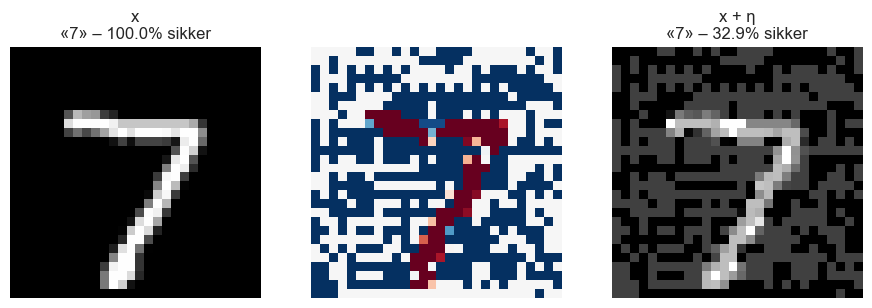

In [5]:
eps = 0.25
idx = 0
x0, y0 = X_ev[idx:idx + 1], y_ev[idx:idx + 1]
x_adv = fgsm(cnn, x0, y0, eps).numpy()
p0, p_adv = cnn.predict(x0, verbose=0)[0], cnn.predict(x_adv, verbose=0)[0]

fig, ax = plt.subplots(1, 3, figsize=(11, 4))
ax[0].imshow(x0[0, :, :, 0], cmap="gray")
ax[0].set_title(f"x\n«{p0.argmax()}» – {p0.max():.1%} sikker")
ax[1].imshow((x_adv - x0)[0, :, :, 0], cmap="RdBu", vmin=-eps, vmax=eps)
ax[2].imshow(x_adv[0, :, :, 0], cmap="gray")
ax[2].set_title(f"x + η\n«{p_adv.argmax()}» – {p_adv.max():.1%} sikker")
for a in ax: a.axis("off")
plt.show()

## 2. Målrettede angrep


In [ ]:
def fgsm_malrettet(modell, x, maal, eps):
    x = tf.convert_to_tensor(x)
    with tf.GradientTape() as tape:
        tape.watch(x)
        tap = tap_fn(maal, modell(x))
    return tf.clip_by_value(x - eps * tf.sign(tape.gradient(tap, x)), 0.0, 1.0)

def iterativt_malrettet(modell, x, maal, eps, steg=10):
    x = tf.convert_to_tensor(x)
    x_adv = x
    for _ in range(steg):
        x_adv = fgsm_malrettet(modell, x_adv, maal, eps / 4)
        x_adv = tf.clip_by_value(x_adv, x - eps, x + eps)
    return x_adv

MAAL = 3
utvalg = y_ev != MAAL
x_u, maal = X_ev[utvalg], np.full(utvalg.sum(), MAAL)
for e in [0.1, 0.2, 0.3]:
    ett_steg = (cnn.predict(fgsm_malrettet(cnn, x_u, maal, e), verbose=0).argmax(1) == MAAL).mean()
    fler_steg = (cnn.predict(iterativt_malrettet(cnn, x_u, maal, e), verbose=0).argmax(1) == MAAL).mean()
    print(f"ε = {e}: andel klassifisert som «{MAAL}» – ett steg: {ett_steg:.1%}, iterativt: {fler_steg:.1%}")

ε = 0.1: andel klassifisert som «3» – ett steg: 3.6%, iterativt: 8.1%
ε = 0.2: andel klassifisert som «3» – ett steg: 23.8%, iterativt: 94.1%
ε = 0.3: andel klassifisert som «3» – ett steg: 62.3%, iterativt: 100.0%


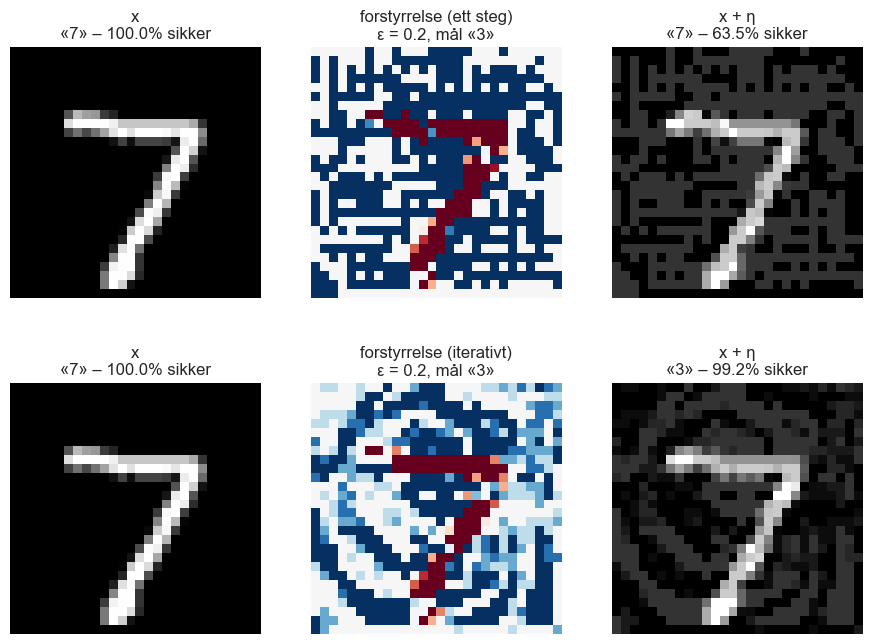

In [7]:
e = 0.2
maal0 = np.array([MAAL])
p0 = cnn.predict(x0, verbose=0)[0]

fig, ax = plt.subplots(2, 3, figsize=(11, 8))
for rad, (navn, angrep) in enumerate([("ett steg", fgsm_malrettet), ("iterativt", iterativt_malrettet)]):
    x_adv = angrep(cnn, x0, maal0, e).numpy()
    p_adv = cnn.predict(x_adv, verbose=0)[0]
    ax[rad, 0].imshow(x0[0, :, :, 0], cmap="gray"); ax[rad, 0].set_title(f"x\n«{p0.argmax()}» – {p0.max():.1%} sikker")
    ax[rad, 1].imshow((x_adv - x0)[0, :, :, 0], cmap="RdBu", vmin=-e, vmax=e); ax[rad, 1].set_title(f"forstyrrelse ({navn})\nε = {e}, mål «{MAAL}»")
    ax[rad, 2].imshow(x_adv[0, :, :, 0], cmap="gray"); ax[rad, 2].set_title(f"x + η\n«{p_adv.argmax()}» – {p_adv.max():.1%} sikker")
for a in ax.flat: a.axis("off")
plt.show()

## 3. Forsvar: adversarial training

In [8]:
robust = lag_cnn("robust_cnn")
opt = tf.keras.optimizers.Adam(1e-3)
ALFA, EPS = 0.5, 0.25

@tf.function # brukes når man vil kompilere funksjonen til TensorFlow-graf for bedre ytelse
def treningssteg(xb, yb):
    with tf.GradientTape() as tape_x:    
        tape_x.watch(xb)
        tap_x = tap_fn(yb, robust(xb, training=False))
    x_adv = tf.clip_by_value(xb + EPS * tf.sign(tape_x.gradient(tap_x, xb)), 0.0, 1.0)

    with tf.GradientTape() as tape:
        tap = ALFA * tap_fn(yb, robust(xb, training=True)) + (1 - ALFA) * tap_fn(yb, robust(x_adv, training=True))
    grads = tape.gradient(tap, robust.trainable_variables)
    opt.apply_gradients(zip(grads, robust.trainable_variables))
    return tap

ds = tf.data.Dataset.from_tensor_slices((X_tr, y_tr)).shuffle(60_000, seed=0).batch(128)
for epoke in range(3):
    loss = [float(treningssteg(xb, yb)) for xb, yb in ds]
    print(f"Epoke {epoke + 1}: gjennomsnittlig tap {np.mean(loss):.4f}")

Epoke 1: gjennomsnittlig tap 0.5572
Epoke 2: gjennomsnittlig tap 0.1671
Epoke 3: gjennomsnittlig tap 0.1980


In [10]:
def evaluer(modell, x, y):
    p = modell.predict(x, verbose=0, batch_size=500)
    feil = p.argmax(axis=1) != y
    return {"nøyaktighet": 1 - feil.mean(), "konfidens på feil": p.max(axis=1)[feil].mean() if feil.any() else np.nan}

sammenligning = pd.DataFrame({
    "standard CNN": {
        "ren testnøyaktighet": evaluer(cnn, X_ev, y_ev)["nøyaktighet"],
        "etter FGSM": evaluer(cnn, fgsm(cnn, X_ev, y_ev, 0.25), y_ev)["nøyaktighet"],
        "konfidens på feil": evaluer(cnn, fgsm(cnn, X_ev, y_ev, 0.25), y_ev)["konfidens på feil"],
    },
    "adversarial trent CNN": {
        "ren testnøyaktighet": evaluer(robust, X_ev, y_ev)["nøyaktighet"],
        "etter FGSM": evaluer(robust, fgsm(robust, X_ev, y_ev, 0.25), y_ev)["nøyaktighet"],
        "konfidens på feil": evaluer(robust, fgsm(robust, X_ev, y_ev, 0.25), y_ev)["konfidens på feil"],

    },
}).round(3)

sammenligning

,standard CNN,adversarial trent CNN
ren testnøyaktighet,0.984,0.982
etter FGSM,0.217,0.978
konfidens på feil,0.787,0.624
